# Brand Popularity and Customer Preference Analysis
EDAV Python course-end project. Uses UCI Online Retail transaction data.

> Note: the dataset has product descriptions, not explicit brands or satisfaction ratings. We analyze product popularity and purchase behavior as proxies.


## 1. Install dependencies
Run `python -m pip install -r requirements.txt` in the VS Code terminal before executing the notebook.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src' / 'analyze_retail.py').exists() and (ROOT.parent / 'src' / 'analyze_retail.py').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from analyze_retail import load_data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
df = load_data()
df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Inspect and clean data


In [2]:
print('Shape:', df.shape)
display(df.info())
display(df.isna().sum())
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['UnitPrice'] = pd.to_numeric(df['UnitPrice'], errors='coerce')
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
sales = df.dropna(subset=['Description','InvoiceDate','Quantity','UnitPrice','InvoiceNo']).copy()
sales = sales[~sales['InvoiceNo'].str.upper().str.startswith('C') & (sales['Quantity'] > 0) & (sales['UnitPrice'] > 0)].copy()
sales['Revenue'] = sales['Quantity'] * sales['UnitPrice']
sales['Month'] = sales['InvoiceDate'].dt.to_period('M').astype(str)
sales.shape


Shape: (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


None

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

(530104, 10)

## 3. Top products by units sold


,Description,UnitsSold,Revenue,TransactionLines
2387,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
2052,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,250
3934,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047,13841.85,537
1816,JUMBO BAG RED RETROSPOT,48474,94340.05,2112
3844,WHITE HANGING HEART T-LIGHT HOLDER,37891,106292.77,2323
2681,POPCORN HOLDER,36761,34298.87,829
227,ASSORTED COLOUR BIRD ORNAMENT,36461,59094.93,1489
2337,PACK OF 72 RETROSPOT CAKE CASES,36419,21259.10,1370
2741,RABBIT NIGHT LIGHT,30788,66964.99,1036
2107,MINI PAINT SET VINTAGE,26633,16937.82,380


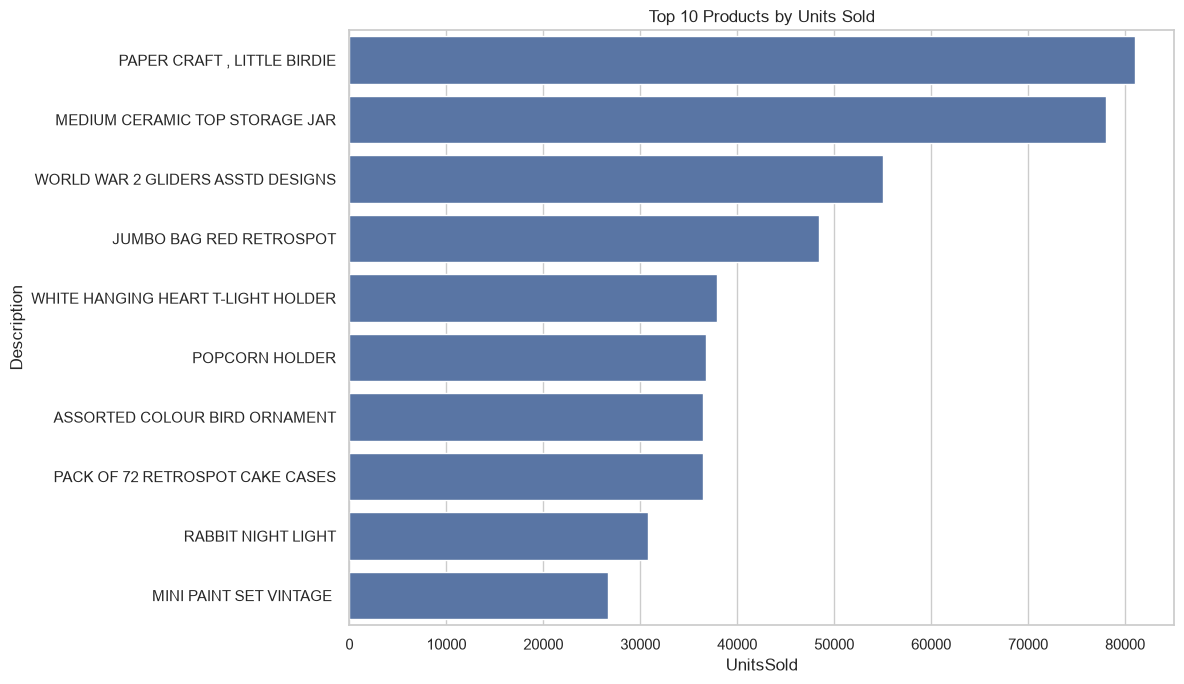

In [3]:
top_products = sales.groupby('Description', as_index=False).agg(UnitsSold=('Quantity','sum'), Revenue=('Revenue','sum'), TransactionLines=('InvoiceNo','count')).sort_values('UnitsSold', ascending=False).head(10)
display(top_products)
plt.figure(figsize=(12,7))
sns.barplot(data=top_products, y='Description', x='UnitsSold')
plt.title('Top 10 Products by Units Sold'); plt.tight_layout(); plt.show()


## 4. Revenue by country


,Country,Revenue
36,United Kingdom,9025222.084
24,Netherlands,285446.340
10,EIRE,283453.960
14,Germany,228867.140
13,France,209715.110
0,Australia,138521.310
31,Spain,61577.110
33,Switzerland,57089.900
3,Belgium,41196.340
32,Sweden,38378.330


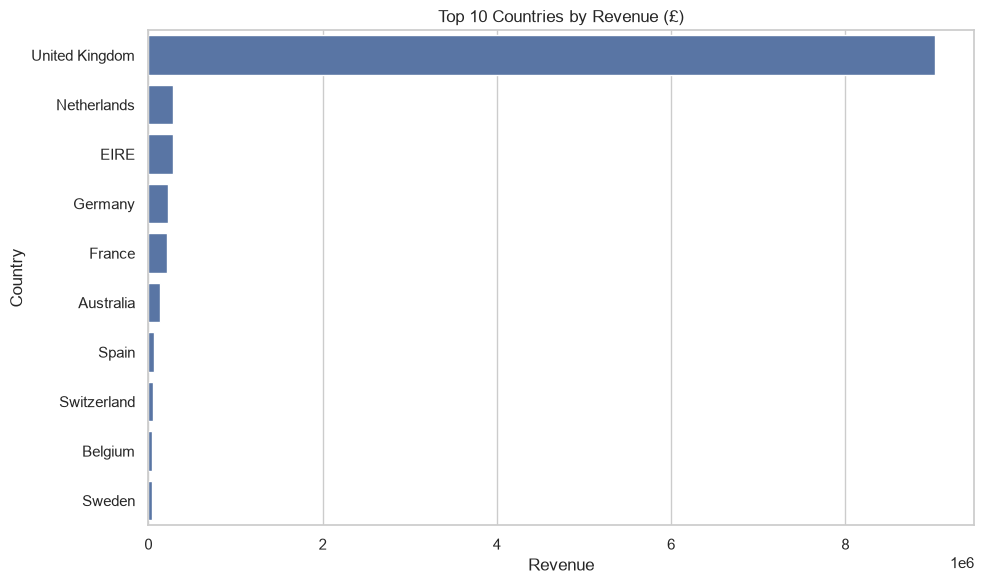

In [4]:
country = sales.groupby('Country', as_index=False)['Revenue'].sum().sort_values('Revenue', ascending=False).head(10)
display(country)
plt.figure(figsize=(10,6))
sns.barplot(data=country, y='Country', x='Revenue')
plt.title('Top 10 Countries by Revenue (£)'); plt.tight_layout(); plt.show()


## 5. Monthly revenue trend


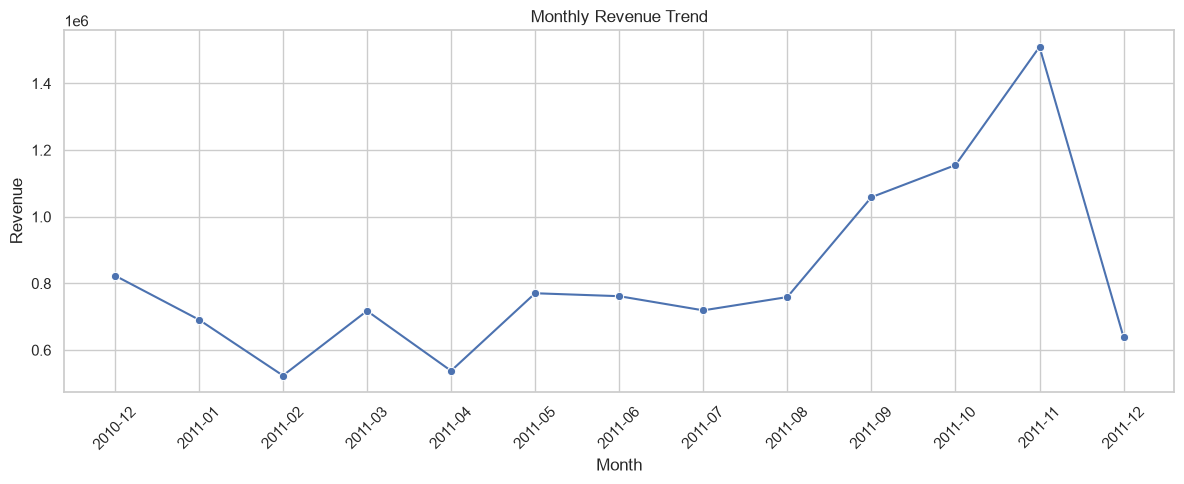

In [5]:
monthly = sales.groupby('Month', as_index=False)['Revenue'].sum()
plt.figure(figsize=(12,5))
sns.lineplot(data=monthly, x='Month', y='Revenue', marker='o')
plt.xticks(rotation=45); plt.title('Monthly Revenue Trend'); plt.tight_layout(); plt.show()


## 6. Repeat purchasing among identified customers
This metric excludes transactions without a CustomerID and measures the share of identified customers with more than one distinct invoice.


In [6]:
if 'CustomerID' in sales.columns:
    known = sales.dropna(subset=['CustomerID'])
    orders = known.groupby('CustomerID')['InvoiceNo'].nunique()
    repeat_share = (orders.gt(1).mean() * 100) if len(orders) else np.nan
    print(f'Identified customers: {orders.size:,}')
    print(f'Customers with more than one invoice: {orders.gt(1).sum():,}')
    print(f'Repeat-customer share: {repeat_share:.2f}%' if pd.notna(repeat_share) else 'Not available')


Identified customers: 4,338
Customers with more than one invoice: 2,845
Repeat-customer share: 65.58%


## 7. Run the full pipeline and save charts / summaries


In [7]:
from analyze_retail import main
main()


Analysis complete.
Rows before cleaning: 541,909
Valid sales rows: 530,104
Unique products: 4,026
Unique invoices: 19,960
Total revenue: £10,666,684.54
Charts saved to: D:\Brand_Popularity_Customer_Preference_Analysis\visualizations
Summary saved to: D:\Brand_Popularity_Customer_Preference_Analysis\report
